In [1]:
from qutip import *
import numpy as np
import scipy as sp
import math
import matplotlib.pyplot as plt
from scipy.special import genlaguerre as L
from scipy.optimize import root_scalar as root
from matplotlib import colormaps as cm
import matplotlib.ticker as ticker

In [11]:
def psi(g,e):
    return np.array([g, e])

def pulse(t, Omega0, delta, phi0, phi1):
    Omega = np.sqrt(Omega0**2 + delta**2)
    
    if Omega == 0.0:
        U = np.array([[1.0 , 0.0],
                      [0.0 , 1.0]])
        
    else:
        U = np.array([[np.cos(Omega*t/2.0) -(1.0j*delta/Omega)*np.sin(Omega*t/2.0), (1.0j*Omega0/Omega)*np.sin(Omega*t/2.0)],
                     [(1.0j*Omega0/Omega)*np.sin(Omega*t/2.0) , np.cos(Omega*t/2.0) + (1.0j*delta/Omega)*np.sin(Omega*t/2.0)]])
    
    V1 = np.array([[1.0 , 0.0],
                   [0.0 , np.exp(-1.0j*phi1)]])
    
    V0 = np.array([[1.0 , 0.0],
                   [0.0 , np.exp(1.0j*phi0)]])
    
    return np.exp(1.0j*delta*t/2.0)*V1@U@V0

def rhogg(psi):
    return (abs(psi[0]))**2.0

def rhoee(psi):
    return (abs(psi[1]))**2.0

In [12]:
fe2 = 688358979309308.22

In [37]:
psi0 = psi(1.+0j, 0.+0j)
t = 1e-3
Omega0 = 1.0*np.pi/(2*t)
delta = 2*np.pi*fe2*4e-19*15**2
T = 50e-3
#taken from the 4e-19 light shift on the rabi E2 for a 30 ms rabi pulse and then scaled to our 1 ms pi/2 pulses
#because rabi rate is proportional to sqrt(I) and the light shift is proportional to I
def ramseyES(deld):
    psiP = rhoee(pulse(t, Omega0, delta+deld, 0, 0)@pulse(T,0,deld,0,np.pi/2.)@pulse(t, Omega0, delta+deld, 0, 0)@psi0)
    psiM = rhoee(pulse(t, Omega0, delta+deld, 0, 0)@pulse(T,0,deld,0,-np.pi/2.)@pulse(t, Omega0, delta+deld, 0, 0)@psi0)
    return psiP-psiM

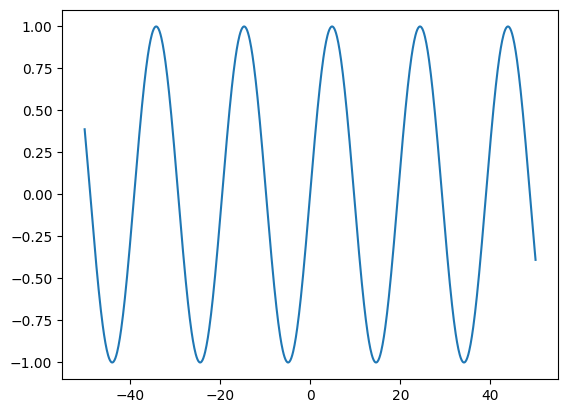

In [38]:
pts = 1000
delds = np.linspace(-2*np.pi*50, 2*np.pi*50, pts)
ESpts = np.zeros(pts)
for ii in range(pts):
    ESpts[ii] = ramseyES(delds[ii])
plt.plot(delds/(2*np.pi), ESpts)

In [39]:
x0 = -1*2*np.pi
x1 = 1*2*np.pi
tol = 1e-10
root(ramseyES, bracket=[x0,x1], xtol = tol).root/(2.*np.pi)/fe2*1e18

-2.2349194186051164

# 